# Ingesta y Auditoría de Microdatos ENAHO (2024 - 2025)
## Módulos 01, 02, 03, 05 y 34 — Lima Metropolitana y Callao (`DOMINIO == 8`)

> **Curso:** Inteligencia Artificial (1INF24) — Pontificia Universidad Católica del Perú (PUCP)  
> **Objetivo de este Notebook:** Cargar, auditar y verificar la integridad de los microdatos de la ENAHO (INEI) para 2024 y 2025, estandarizando las columnas técnicas a **nombres descriptivos según los Diccionarios Metodológicos Oficiales del INEI**, garantizando lectura precisa y cero imputación prematura.

In [17]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
import pandas as pd
import numpy as np

# Configurar acceso a src/
ROOT_DIR = Path.cwd().resolve()
if ROOT_DIR.name == "notebooks":
    ROOT_DIR = ROOT_DIR.parent
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

from src.io_enaho import (
    load_modulo34,
    load_modulo01,
    load_modulo02,
    load_modulo03,
    load_modulo05,
    KEY_HOGAR,
    KEY_PERSONA,
)

print(f"✓ Entorno configurado correctamente. Raíz del proyecto: {ROOT_DIR}")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
✓ Entorno configurado correctamente. Raíz del proyecto: /Users/gaelarias/Documents/PUCP/2026-2/Inteligencia Artificial/Tarea Académica


---  
## 1. Módulo 34: Sumaria (Resumen de Hogares, Pobreza y Target)

- **Nivel:** Hogar (`conglomerado`, `vivienda`, `hogar`).
- **Filtro:** `dominio == 8` (Lima Metropolitana y Callao).
- **Columnas estandarizadas:** `pobreza_oficial`, `target_pobreza` (1 = Pobre, 0 = No pobre), `factor_expansion`, `miembros_hogar`, `gasto_anual_hogar`, `linea_pobreza`, `lngpc`.

In [18]:
m34_2024 = load_modulo34(2024, data_root=ROOT_DIR / "Data")
m34_2025 = load_modulo34(2025, data_root=ROOT_DIR / "Data")

print(f"[Módulo 34 - 2024] Hogares: {len(m34_2024):,d} | Pobres: {m34_2024['target_pobreza'].sum():,d} ({m34_2024['target_pobreza'].mean():.2%})")
print(f"[Módulo 34 - 2025] Hogares: {len(m34_2025):,d} | Pobres: {m34_2025['target_pobreza'].sum():,d} ({m34_2025['target_pobreza'].mean():.2%})")
display(m34_2024.head(5))

[Módulo 34 - 2024] Hogares: 4,090 | Pobres: 774 (18.92%)
[Módulo 34 - 2025] Hogares: 4,129 | Pobres: 734 (17.78%)


,conglomerado,vivienda,hogar,ubigeo,dominio,estrato,miembros_hogar,gasto_anual_hogar,linea_pobreza,pobreza_oficial,factor_expansion,target_pobreza,y,lngpc
0,016166,010,11,070104,8,1,5,58032.730469,559.219971,3,110.749878,0,0,6.874418
1,016166,042,11,070104,8,1,2,82402.148438,559.219971,3,110.749878,0,0,8.141313
2,016166,057,11,070104,8,1,6,156289.312500,559.219971,3,110.749878,0,0,7.682798
3,016166,072,11,070104,8,1,5,69796.414062,559.219971,3,110.749878,0,0,7.058993
4,016166,101,11,070104,8,1,2,35185.167969,559.219971,3,110.749878,0,0,7.290326


---  
## 2. Módulo 01: Características de la Vivienda y del Hogar

- **Nivel:** Hogar.
- **Filtro:** `resultado_encuesta in [1, 2]`.
- **Columnas estandarizadas:** `tipo_vivienda`, `material_pared`, `material_piso`, `total_habitaciones`, `total_dormitorios`, `tenencia_vivienda`, `titulo_propiedad`, `registro_sunarp`, `fuente_agua`, `conexion_bano`, `combustible_cocina`, `tiene_internet`, `es_hogar_secundario`.
- **Diagnóstico Crítico (Observación del Jurado):** Conservación estricta de valores nulos (`NaN`) en hogares secundarios (`es_hogar_secundario == 1`). **Cero rellenado automático `ffill/bfill`**.

In [19]:
m01_2024 = load_modulo01(2024, data_root=ROOT_DIR / "Data")
m01_2025 = load_modulo01(2025, data_root=ROOT_DIR / "Data")

# Delimitar a hogares de Lima Metropolitana
hogares_lima_2024 = m34_2024[KEY_HOGAR].drop_duplicates()
hogares_lima_2025 = m34_2025[KEY_HOGAR].drop_duplicates()

m01_2024 = m01_2024.merge(hogares_lima_2024, on=KEY_HOGAR, how="inner")
m01_2025 = m01_2025.merge(hogares_lima_2025, on=KEY_HOGAR, how="inner")

print(f"[Módulo 01 - 2024] Registros: {len(m01_2024):,d} | Hogares secundarios: {(m01_2024['es_hogar_secundario'] == 1).sum()}")
print(f"                  Nulos sin imputar en tipo_vivienda:     {m01_2024['tipo_vivienda'].isna().sum()}")
print(f"                  Nulos sin imputar en total_habitaciones: {m01_2024['total_habitaciones'].isna().sum()}")

print(f"[Módulo 01 - 2025] Registros: {len(m01_2025):,d} | Hogares secundarios: {(m01_2025['es_hogar_secundario'] == 1).sum()}")
print(f"                  Nulos sin imputar en tipo_vivienda:     {m01_2025['tipo_vivienda'].isna().sum()}")
print(f"                  Nulos sin imputar en total_habitaciones: {m01_2025['total_habitaciones'].isna().sum()}")
display(m01_2024.head(5))

[Módulo 01 - 2024] Registros: 4,090 | Hogares secundarios: 146
                  Nulos sin imputar en tipo_vivienda:     72
                  Nulos sin imputar en total_habitaciones: 72
[Módulo 01 - 2025] Registros: 4,129 | Hogares secundarios: 178
                  Nulos sin imputar en tipo_vivienda:     96
                  Nulos sin imputar en total_habitaciones: 96


,conglomerado,vivienda,hogar,dominio,ubigeo,resultado_encuesta,tipo_vivienda,material_pared,material_piso,total_habitaciones,...,combustible_cocina,tiene_tv_cable,tiene_internet,nbi_vivienda_inadecuada,nbi_hacinamiento,nbi_sin_bano,nbi_nino_sin_escuela,nbi_alta_dependencia,es_hogar_secundario,sin_datos_vivienda
0,016184,112,11,8,070101,2,1.0,1.0,3.0,3.0,...,3.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0,0
1,016256,006,11,8,070101,2,1.0,1.0,5.0,4.0,...,2.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0,0
2,016242,042,11,8,070101,2,1.0,1.0,5.0,3.0,...,2.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0,0
3,016285,082,11,8,070101,1,1.0,1.0,3.0,1.0,...,2.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0
4,016201,144,11,8,070101,1,2.0,1.0,5.0,2.0,...,2.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0,0


---  
## 3. Módulo 02: Demografía y Características de los Miembros

- **Nivel:** Persona (`conglomerado`, `vivienda`, `hogar`, `cod_persona`).
- **Filtro:** Residentes habituales (`es_miembro_habitual == 1` y no ausente).
- **Columnas estandarizadas:** `parentesco_jefe`, `sexo` (1: Hombre, 2: Mujer), `edad`, `estado_civil`.

In [20]:
m02_2024 = load_modulo02(2024, data_root=ROOT_DIR / "Data").merge(hogares_lima_2024, on=KEY_HOGAR, how="inner")
m02_2025 = load_modulo02(2025, data_root=ROOT_DIR / "Data").merge(hogares_lima_2025, on=KEY_HOGAR, how="inner")

print(f"[Módulo 02 - 2024] Residentes: {len(m02_2024):,d} en {m02_2024[KEY_HOGAR].drop_duplicates().shape[0]:,d} hogares")
print(f"[Módulo 02 - 2025] Residentes: {len(m02_2025):,d} en {m02_2025[KEY_HOGAR].drop_duplicates().shape[0]:,d} hogares")
display(m02_2024.head(5))

[Módulo 02 - 2024] Residentes: 13,563 en 4,090 hogares
[Módulo 02 - 2025] Residentes: 13,515 en 4,129 hogares


,conglomerado,vivienda,hogar,cod_persona,parentesco_jefe,es_miembro_habitual,ausente_mas_3_meses,presente_mas_3_meses,sexo,edad,estado_civil
0,016165,019,11,01,1,1.0,2.0,NaN,1.0,66.0,2.0
1,016165,019,11,02,2,1.0,2.0,NaN,2.0,60.0,2.0
2,016165,019,11,03,3,1.0,2.0,NaN,1.0,35.0,6.0
3,016165,053,11,01,1,1.0,2.0,NaN,2.0,63.0,5.0
4,016165,073,11,01,1,1.0,2.0,NaN,1.0,63.0,3.0


---  
## 4. Módulo 03: Educación y Capital Humano

- **Nivel:** Persona (miembros $\ge 3$ años).
- **Columnas estandarizadas:** `parentesco_jefe`, `lengua_materna`, `nivel_educativo`, `sabe_leer_escribir`, `asiste_centro_educativo`, `tipo_institucion_educ`.

In [21]:
m03_2024 = load_modulo03(2024, data_root=ROOT_DIR / "Data").merge(hogares_lima_2024, on=KEY_HOGAR, how="inner")
m03_2025 = load_modulo03(2025, data_root=ROOT_DIR / "Data").merge(hogares_lima_2025, on=KEY_HOGAR, how="inner")

print(f"[Módulo 03 - 2024] Personas evaluadas: {len(m03_2024):,d} en {m03_2024[KEY_HOGAR].drop_duplicates().shape[0]:,d} hogares")
print(f"[Módulo 03 - 2025] Personas evaluadas: {len(m03_2025):,d} en {m03_2025[KEY_HOGAR].drop_duplicates().shape[0]:,d} hogares")
display(m03_2024.head(5))

[Módulo 03 - 2024] Personas evaluadas: 13,334 en 4,090 hogares
[Módulo 03 - 2025] Personas evaluadas: 13,360 en 4,129 hogares


,conglomerado,vivienda,hogar,cod_persona,lengua_materna,nivel_educativo,sabe_leer_escribir,asiste_centro_educativo,tipo_institucion_educ,parentesco_jefe
0,016166,010,11,01,4,8,NaN,2.0,NaN,1
1,016166,010,11,02,4,3,1.0,2.0,NaN,2
2,016166,010,11,03,4,8,NaN,2.0,NaN,11
3,016166,010,11,04,4,3,2.0,2.0,NaN,11
4,016166,010,11,05,4,5,NaN,2.0,NaN,7


---  
## 5. Módulo 05: Empleo e Informalidad Laboral

- **Nivel:** Persona (PET $\ge 14$ años).
- **Columnas estandarizadas:** `condicion_actividad` (1: Ocupado), `categoria_ocupacional`, `empresa_tiene_ruc`, `horas_semanales_trabajadas`, `afiliacion_pension` (5: Sin pensión).
- **Blindaje metodológico:** Exclusión estricta de ingresos laborales/no laborales (cero *data leakage*).

In [22]:
m05_2024 = load_modulo05(2024, data_root=ROOT_DIR / "Data").merge(hogares_lima_2024, on=KEY_HOGAR, how="inner")
m05_2025 = load_modulo05(2025, data_root=ROOT_DIR / "Data").merge(hogares_lima_2025, on=KEY_HOGAR, how="inner")

print(f"[Módulo 05 - 2024] Personas en edad de trabajar: {len(m05_2024):,d} en {m05_2024[KEY_HOGAR].drop_duplicates().shape[0]:,d} hogares")
print(f"[Módulo 05 - 2025] Personas en edad de trabajar: {len(m05_2025):,d} en {m05_2025[KEY_HOGAR].drop_duplicates().shape[0]:,d} hogares")
display(m05_2024.head(5))

[Módulo 05 - 2024] Personas en edad de trabajar: 11,335 en 4,090 hogares
[Módulo 05 - 2025] Personas en edad de trabajar: 11,419 en 4,129 hogares


,conglomerado,vivienda,hogar,cod_persona,categoria_ocupacional,empresa_tiene_ruc,horas_semanales_trabajadas,afiliacion_pension,parentesco_jefe,condicion_actividad
0,016166,010,11,01,3.0,NaN,37.0,0.0,1,1
1,016166,010,11,02,NaN,NaN,NaN,5.0,2,4
2,016166,010,11,03,3.0,1.0,44.0,5.0,11,1
3,016166,010,11,04,NaN,NaN,NaN,0.0,11,3
4,016166,010,11,05,NaN,NaN,NaN,5.0,7,4


---  
## 6. Matriz Consolidada de Auditoría de Microdatos (2024 vs. 2025)

Cotejo de integridad dimensional y validación de unicidad de llaves primarias (`PK`).

In [23]:
def audit_year_modules(year: int, mods: dict) -> pd.DataFrame:
    rows = []
    for name, df in mods.items():
        pk = KEY_HOGAR if name in ["modulo34", "modulo01"] else KEY_PERSONA
        rows.append({
            "Año": year,
            "Módulo": name,
            "Nivel": "Hogar" if name in ["modulo34", "modulo01"] else "Persona",
            "Filas Totales": len(df),
            "Hogares Únicos": df[KEY_HOGAR].drop_duplicates().shape[0],
            "Columnas": df.shape[1],
            "PK Única": not df.duplicated(subset=pk).any(),
        })
    return pd.DataFrame(rows)

mods_2024_all = {
    "modulo34": m34_2024,
    "modulo01": m01_2024,
    "modulo02": m02_2024,
    "modulo03": m03_2024,
    "modulo05": m05_2024,
}

mods_2025_all = {
    "modulo34": m34_2025,
    "modulo01": m01_2025,
    "modulo02": m02_2025,
    "modulo03": m03_2025,
    "modulo05": m05_2025,
}

audit_df = pd.concat([audit_year_modules(2024, mods_2024_all), audit_year_modules(2025, mods_2025_all)], ignore_index=True)
display(audit_df)

,Año,Módulo,Nivel,Filas Totales,Hogares Únicos,Columnas,PK Única
0,2024,modulo34,Hogar,4090,4090,14,True
1,2024,modulo01,Hogar,4090,4090,27,True
2,2024,modulo02,Persona,13563,4090,11,True
3,2024,modulo03,Persona,13334,4090,10,True
4,2024,modulo05,Persona,11335,4090,10,True
5,2025,modulo34,Hogar,4129,4129,14,True
6,2025,modulo01,Hogar,4129,4129,27,True
7,2025,modulo02,Persona,13515,4129,11,True
8,2025,modulo03,Persona,13360,4129,10,True
9,2025,modulo05,Persona,11419,4129,10,True


---
## 7. Consolidación del Big DataFrame a Nivel Hogar (Operador $\Phi$)

Integración horizontal de los 5 módulos en una sola tabla tabular a nivel hogar utilizando `src.dataset.build_master_dataset()`:
- **Reducción relacional:** Miembros colapsados a hogar (rama de jefatura y funcionales agregados de menores, adultos mayores y educación).
- **Fusión horizontal:** Enlace con Módulo 34 y Módulo 01 por la llave primaria `['conglomerado', 'vivienda', 'hogar']`.
- **Blindaje Anti-Fuga (OOT):** Purga estricta de los 930 hogares panel en 2025 ($N_{\text{test}} = 3{,}199$).
- **Delimitación estricta:** Cero preprocesamiento todavía (nulos, outliers y formatos se mantienen intactos para la fase subsiguiente).

In [24]:
from src.dataset import build_master_dataset

df_2024 = build_master_dataset(2024, data_root=ROOT_DIR / "Data")
df_2025_test = build_master_dataset(2025, data_root=ROOT_DIR / "Data", purge_panel_2025=True)

print(f"✓ Big DF 2024 (Train/Val): {df_2024.shape} | Pobres: {df_2024['target_pobreza'].sum():,d} ({df_2024['target_pobreza'].mean():.2%})")
print(f"✓ Big DF 2025 (Test OOT):  {df_2025_test.shape} | Pobres: {df_2025_test['target_pobreza'].sum():,d} ({df_2025_test['target_pobreza'].mean():.2%})")
display(df_2024.head(5))

[build_master_dataset 2025] Purga de panel: 930 hogares repetidos eliminados.
✓ Big DF 2024 (Train/Val): (4090, 55) | Pobres: 774 (18.92%)
✓ Big DF 2025 (Test OOT):  (3199, 55) | Pobres: 557 (17.41%)


,conglomerado,vivienda,hogar,ubigeo,dominio,estrato,miembros_hogar,gasto_anual_hogar,linea_pobreza,pobreza_oficial,...,educ_jefe,n_ocupados,jefe_ocupado,jefe_horas_semanales,jefe_cat_ocupacional,jefe_empresa_ruc,jefe_sin_pension,personas_por_hab,ocupados_por_miembro,anio_encuesta
0,016166,010,11,070104,8,1,5,58032.730469,559.219971,3,...,8.0,2,1.0,37.0,3.0,0.0,0.0,1.666667,0.400000,2024
1,016166,042,11,070104,8,1,2,82402.148438,559.219971,3,...,10.0,1,1.0,25.0,3.0,1.0,0.0,0.333333,0.500000,2024
2,016166,057,11,070104,8,1,6,156289.312500,559.219971,3,...,9.0,5,1.0,48.0,1.0,1.0,0.0,1.200000,0.833333,2024
3,016166,072,11,070104,8,1,5,69796.414062,559.219971,3,...,10.0,1,0.0,0.0,0.0,0.0,0.0,0.833333,0.200000,2024
4,016166,101,11,070104,8,1,2,35185.167969,559.219971,3,...,6.0,2,1.0,64.0,3.0,0.0,0.0,0.666667,1.000000,2024


In [26]:
# Inventario de columnas del Big DataFrame consolidado
print(f"Total variables en el Big DF: {len(df_2024.columns)}")
print(list(df_2024.columns))

Total variables en el Big DF: 55
['conglomerado', 'vivienda', 'hogar', 'ubigeo', 'dominio', 'estrato', 'miembros_hogar', 'gasto_anual_hogar', 'linea_pobreza', 'pobreza_oficial', 'factor_expansion', 'target_pobreza', 'y', 'lngpc', 'resultado_encuesta', 'tipo_vivienda', 'material_pared', 'material_piso', 'total_habitaciones', 'total_dormitorios', 'tenencia_vivienda', 'titulo_propiedad', 'registro_sunarp', 'fuente_agua', 'agua_todos_los_dias', 'conexion_bano', 'combustible_cocina', 'tiene_tv_cable', 'tiene_internet', 'nbi_vivienda_inadecuada', 'nbi_hacinamiento', 'nbi_sin_bano', 'nbi_nino_sin_escuela', 'nbi_alta_dependencia', 'es_hogar_secundario', 'sin_datos_vivienda', 'n_miembros', 'n_ninos_0_5', 'n_menores_14', 'n_mayores_65', 'jefe_mujer', 'jefe_edad', 'jefe_estado_civil', 'tasa_dependencia', 'educ_max_hogar', 'educ_jefe', 'n_ocupados', 'jefe_ocupado', 'jefe_horas_semanales', 'jefe_cat_ocupacional', 'jefe_empresa_ruc', 'jefe_sin_pension', 'personas_por_hab', 'ocupados_por_miembro', 'a

---
## 8. Selección Canónica del Espacio de Características ($\mathbf{x}_i \in \mathbb{R}^{28}$)

De las 54 columnas integradas en el Big DataFrame, delimitamos estrictamente las **28 características canónicas** formalizadas en la Sección 3 del informe metodológico:
$$\mathbf{x}_i = [\mathbf{x}_i^{(\text{viv})}, \mathbf{x}_i^{(\text{dem})}, \mathbf{x}_i^{(\text{edu})}, \mathbf{x}_i^{(\text{emp})}] \in \mathbb{R}^{28}$$

### Criterios de Exclusión:
1. **14 variables administrativas y de fuga:** Llaves de identificación (`conglomerado`, `vivienda`, `hogar`), geográficas (`ubigeo`, `dominio`, `estrato`), ponderadores (`factor_expansion`), etiquetas oficiales (`pobreza_oficial`, `target_pobreza`, `y`), variables monetarias de fuga (`gasto_anual_hogar`, `linea_pobreza`, `lngpc`) y temporal (`anio_encuesta`).
2. **5 indicadores NBI agregados:** `nbi1_hacinamiento`, `nbi2_vivienda_inadecuada`, `nbi3_sin_desague`, `nbi4_ninos_sin_escuela`, `nbi5_alta_dependencia_baja_educ` (cuasi-constantes en Lima urbana y redundantes con las variables físicas directas).
3. **7 variables intermedias/redundantes:** `miembros_hogar` (duplicado de `n_miembros`), `jefe_estado_civil` (baja capacidad predictiva de pobreza), etc.

In [27]:
from src.preprocessing import (
    NUMERIC_COLS,
    CATEGORICAL_COLS,
    CANONICAL_FEATURES_28,
    TARGET_COL,
    GROUP_COL,
    prepare_xy_data,
    SecondaryHouseholdImputer,
    build_preprocessor,
)

print(f"✓ Total características canónicas: {len(CANONICAL_FEATURES_28)}")
print(f"  • Numéricas / Ratios / Ordinales (14): {NUMERIC_COLS}")
print(f"  • Categóricas / Nominales / Binarias (14): {CATEGORICAL_COLS}")

# Verificación de presencia en el dataset de entrenamiento
missing_in_df = [c for c in CANONICAL_FEATURES_28 if c not in df_2024.columns]
assert len(missing_in_df) == 0, f"Variables faltantes: {missing_in_df}"
print("✓ Todas las 28 variables están presentes en df_2024 y df_2025_test.")

✓ Total características canónicas: 28
  • Numéricas / Ratios / Ordinales (14): ['total_habitaciones', 'total_dormitorios', 'personas_por_hab', 'n_miembros', 'n_ninos_0_5', 'n_menores_14', 'n_mayores_65', 'tasa_dependencia', 'jefe_edad', 'educ_jefe', 'educ_max_hogar', 'n_ocupados', 'ocupados_por_miembro', 'jefe_horas_semanales']
  • Categóricas / Nominales / Binarias (14): ['tipo_vivienda', 'material_pared', 'material_piso', 'tenencia_vivienda', 'fuente_agua', 'agua_todos_los_dias', 'conexion_bano', 'combustible_cocina', 'tiene_internet', 'jefe_mujer', 'jefe_ocupado', 'jefe_cat_ocupacional', 'jefe_empresa_ruc', 'jefe_sin_pension']
✓ Todas las 28 variables están presentes en df_2024 y df_2025_test.


---
## 9. Análisis Exploratorio de Datos (EDA) en ENAHO 2024 (Train/Val)

A continuación realizamos el análisis exploratorio formal sobre la muestra de entrenamiento 2024 ($N = 4{,}090$ hogares) para diagnosticar:
1. Balance de clases y factor de desbalance $\gamma$.
2. Auditoría de valores faltantes (distinguiendo la observación OBS-P01 de nulos estructurales).
3. Distribución de valores atípicos y justificación de preservación (sin poda).
4. Correlaciones lineales y monotónicas con el target de pobreza.
5. Frecuencia de categorías raras (< 1%) y justificación del hiperparámetro `min_frequency`.

=== DISTRIBUCIÓN DE CLASES (ENAHO 2024) ===
Total hogares:       4,090
Hogares no pobres:   3,316 (81.08%)
Hogares pobres (y=1):774 (18.92%)
Razón de desbalance: γ ≈ 4.28 : 1


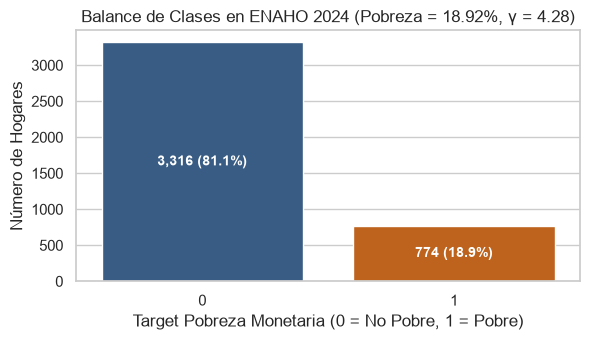

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración estética
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"font.size": 10, "figure.autolayout": True})

# 9.1. Balance de la variable objetivo
n_total = len(df_2024)
n_poor = int(df_2024[TARGET_COL].sum())
n_non_poor = n_total - n_poor
p_poor = n_poor / n_total
gamma = n_non_poor / n_poor

print("=== DISTRIBUCIÓN DE CLASES (ENAHO 2024) ===")
print(f"Total hogares:       {n_total:,d}")
print(f"Hogares no pobres:   {n_non_poor:,d} ({1 - p_poor:.2%})")
print(f"Hogares pobres (y=1):{n_poor:,d} ({p_poor:.2%})")
print(f"Razón de desbalance: γ ≈ {gamma:.2f} : 1")

fig, ax = plt.subplots(figsize=(6, 3.5))
sns.countplot(x=TARGET_COL, data=df_2024, ax=ax, hue=TARGET_COL, palette=["#2b5c8f", "#d95f02"], legend=False)
ax.set_title(f"Balance de Clases en ENAHO 2024 (Pobreza = {p_poor:.2%}, γ = {gamma:.2f})")
ax.set_xlabel("Target Pobreza Monetaria (0 = No Pobre, 1 = Pobre)")
ax.set_ylabel("Número de Hogares")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,d} ({p.get_height()/n_total:.1%})",
                (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                ha="center", va="center", color="white", fontweight="bold")
plt.show()

### 9.2. Auditoría Exhaustiva de Valores Faltantes (Nulos)

Evaluamos los valores faltantes en las 28 variables canónicas antes de cualquier imputación:
- **72 hogares secundarios (1.76%):** Carecen de datos en Módulo 01 (`tipo_vivienda`, `material_pared`, `material_piso`, `total_habitaciones`, `total_dormitorios`). Esto levanta la **OBS-P01**.
- **1,232 jefes inactivos/desempleados:** Tienen nulos en `jefe_horas_semanales`, `jefe_cat_ocupacional` y `jefe_empresa_ruc` porque no trabajan (nulo estructural legítimo).
- **225 hogares sin red de agua continua:** NA en `agua_todos_los_dias`.
- **46 hogares que no cocinan con combustible tradicional:** NA en `combustible_cocina`.

,Variable,Nulos,Porcentaje_Nulos
0,agua_todos_los_dias,225,5.501222
1,total_habitaciones,72,1.760391
2,total_dormitorios,72,1.760391
3,personas_por_hab,72,1.760391
4,tipo_vivienda,72,1.760391
5,material_pared,72,1.760391
6,material_piso,72,1.760391
7,jefe_sin_pension,48,1.173594
8,combustible_cocina,46,1.124694
9,educ_jefe,27,0.660147


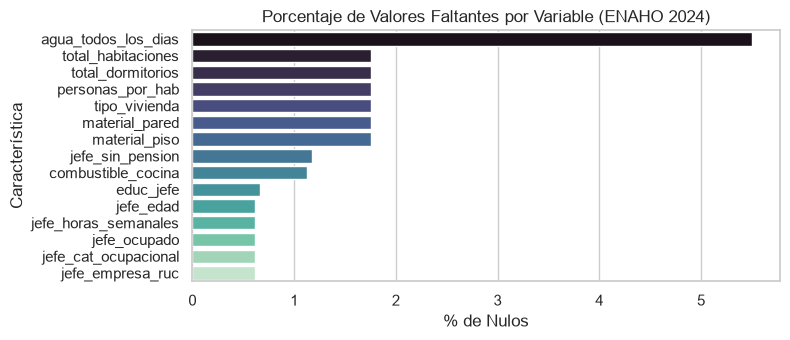

In [30]:
null_summary = df_2024[CANONICAL_FEATURES_28].isnull().sum()
null_df = pd.DataFrame({
    "Variable": null_summary.index,
    "Nulos": null_summary.values,
    "Porcentaje_Nulos": (null_summary.values / len(df_2024)) * 100
})
null_df = null_df[null_df["Nulos"] > 0].sort_values(by="Nulos", ascending=False).reset_index(drop=True)
display(null_df)

fig, ax = plt.subplots(figsize=(8, 3.5))
sns.barplot(data=null_df, x="Porcentaje_Nulos", y="Variable", ax=ax, hue="Variable", palette="mako", legend=False)
ax.set_title("Porcentaje de Valores Faltantes por Variable (ENAHO 2024)")
ax.set_xlabel("% de Nulos")
ax.set_ylabel("Característica")
plt.show()

### 9.3. Estadísticos Descriptivos y Preservación de Valores Atípicos

De acuerdo con la metodología del proyecto y la recomendación de *Grosh et al. (2022)*, **no se realiza recorte ni poda de valores atípicos** (*outliers*) en tamaño de hogar (`n_miembros`), hacinamiento (`personas_por_hab`) ni tasa de dependencia (`tasa_dependencia`). Podar estos extremos excluiría artificialmente a los hogares más vulnerables y desfavorecidos de Lima Metropolitana. La robustez frente a colas pesadas se garantiza mediante:
1. Invarianza monotónica al orden en clasificadores basados en árboles (CART, Random Forest, LightGBM).
2. Escalamiento robusto basado en mediana y rango intercuartílico (`RobustScaler`) en modelos lineales y PMT-MCO.

,Conteo,Media,Desv_Est,Min,Mediana,Max
total_habitaciones,4018.0,3.51,1.53,1.00,3.0,14.0
total_dormitorios,4018.0,2.28,1.13,0.00,2.0,10.0
personas_por_hab,4018.0,1.11,0.78,0.11,1.0,7.0
n_miembros,4090.0,3.31,1.70,1.00,3.0,14.0
n_ninos_0_5,4090.0,0.19,0.44,0.00,0.0,3.0
n_menores_14,4090.0,0.57,0.85,0.00,0.0,6.0
n_mayores_65,4090.0,0.49,0.73,0.00,0.0,5.0
tasa_dependencia,4090.0,0.61,0.68,0.00,0.5,5.0
jefe_edad,4065.0,54.79,15.81,18.00,54.0,97.0
educ_jefe,4063.0,6.73,2.21,1.00,6.0,11.0


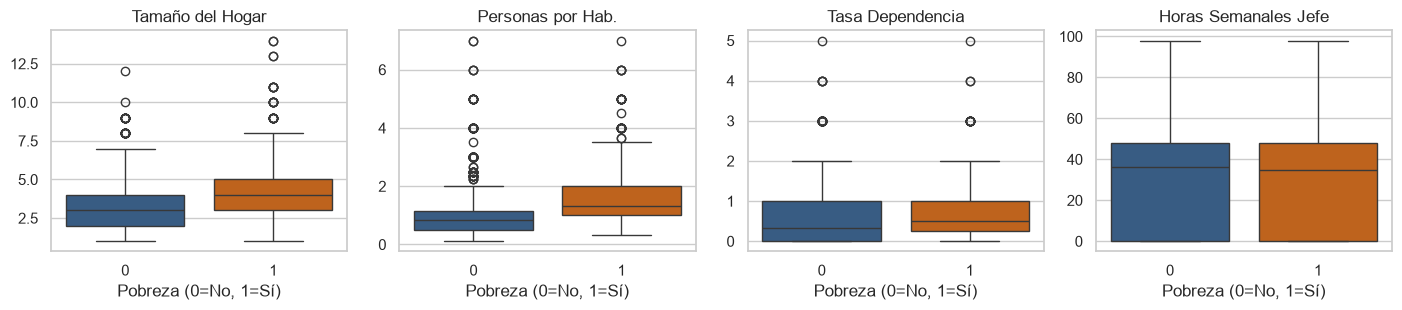

In [31]:
# Estadísticos descriptivos de las variables numéricas
desc = df_2024[NUMERIC_COLS].describe().T[["count", "mean", "std", "min", "50%", "max"]]
desc.columns = ["Conteo", "Media", "Desv_Est", "Min", "Mediana", "Max"]
display(desc.round(2))

# Visualización de distribuciones y outliers clave
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2))
key_outlier_cols = ["n_miembros", "personas_por_hab", "tasa_dependencia", "jefe_horas_semanales"]
titles = ["Tamaño del Hogar", "Personas por Hab.", "Tasa Dependencia", "Horas Semanales Jefe"]

for ax, col, title in zip(axes, key_outlier_cols, titles):
    sns.boxplot(y=col, x=TARGET_COL, data=df_2024, ax=ax, hue=TARGET_COL, palette=["#2b5c8f", "#d95f02"], legend=False)
    ax.set_title(title)
    ax.set_xlabel("Pobreza (0=No, 1=Sí)")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

### 9.4. Correlaciones Lineales con la Pobreza Monetaria

Analizamos la matriz de correlación de Pearson entre las características numéricas y el indicador de pobreza $y_i$.
- **Factores de Riesgo / Vulnerabilidad (+):** `personas_por_hab` (+0.34), `n_menores_14` (+0.33), `n_miembros` (+0.33) y `n_ninos_0_5` (+0.29). A mayor carga infantil y hacinamiento, significativamente mayor probabilidad de pobreza.
- **Factores Protectores (-):** `ocupados_por_miembro` (-0.18), `educ_jefe` (-0.17) y `total_habitaciones` (-0.11). La diversificación laboral y el capital humano del jefe actúan como barreras clave ante la vulnerabilidad económica.

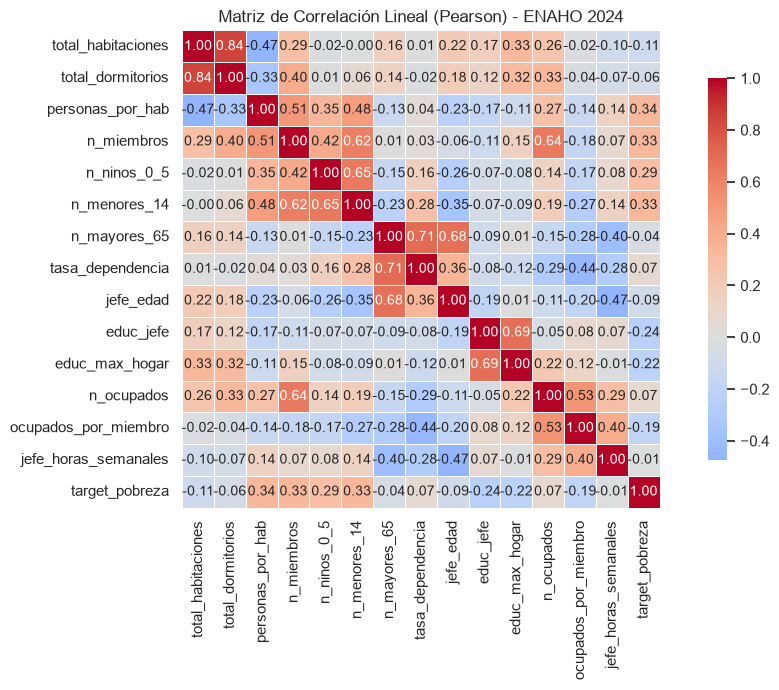

=== CORRELACIÓN CON TARGET_POBREZA ===
target_pobreza          1.000000
personas_por_hab        0.342493
n_miembros              0.331637
n_menores_14            0.330679
n_ninos_0_5             0.285630
n_ocupados              0.073937
tasa_dependencia        0.068314
jefe_horas_semanales   -0.007543
n_mayores_65           -0.041376
total_dormitorios      -0.061810
jefe_edad              -0.090218
total_habitaciones     -0.109118
ocupados_por_miembro   -0.189214
educ_max_hogar         -0.223801
educ_jefe              -0.242455


In [32]:
# Matriz de correlación de Pearson
corr_matrix = df_2024[NUMERIC_COLS + [TARGET_COL]].corr()

fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
    ax=ax
)
ax.set_title("Matriz de Correlación Lineal (Pearson) - ENAHO 2024")
plt.show()

# Ranking de correlación con target_pobreza
print("=== CORRELACIÓN CON TARGET_POBREZA ===")
print(corr_matrix[TARGET_COL].sort_values(ascending=False).to_string())

### 9.5. Categorías Raras y Tasa de Pobreza Condicional

Para evitar la explosión dimensional y el sobreajuste (*overfitting*) en categorías con escasa representatividad (< 1% de la muestra, es decir, < 40 observaciones), el preprocesador agrupará categorías infrecuentes mediante el hiperparámetro `min_frequency=20` en `OneHotEncoder`.

In [33]:
rare_summary = []
for c in CATEGORICAL_COLS:
    vc = df_2024[c].value_counts(dropna=False)
    n_rare = (vc < 40).sum()
    pct_rare = vc[vc < 40].sum() / len(df_2024) * 100
    rare_summary.append({
        "Variable": c,
        "Categorías_Totales": len(vc),
        "Categorías_<40_obs": n_rare,
        "%_Muestra_en_Raras": round(pct_rare, 2)
    })

rare_df = pd.DataFrame(rare_summary).sort_values(by="Categorías_<40_obs", ascending=False).reset_index(drop=True)
display(rare_df)

,Variable,Categorías_Totales,Categorías_<40_obs,%_Muestra_en_Raras
0,material_pared,10,6,2.93
1,combustible_cocina,7,3,0.98
2,tenencia_vivienda,7,2,0.05
3,fuente_agua,6,2,0.68
4,conexion_bano,8,2,0.15
5,jefe_cat_ocupacional,8,2,1.00
6,tipo_vivienda,6,1,0.05
7,material_piso,8,1,0.02
8,jefe_ocupado,3,1,0.61
9,jefe_empresa_ruc,5,1,0.61


---
## 10. Verificación del Preprocesador Anti-Fuga (`src.preprocessing`)

Verificamos la ejecución del pipeline de preprocesamiento completo:
1. `SecondaryHouseholdImputer`: Imputa las 72 viviendas secundarias con la mediana del conglomerado censal y resuelve las horas de jefes no ocupados (**OBS-P01**).
2. `ColumnTransformer`: Escala variables numéricas mediante `RobustScaler()` y codifica las 14 variables categóricas con `OneHotEncoder(min_frequency=20)`.
3. Verificación de integridad: Confirmamos que las matrices $X_{\text{train}}$ y $X_{\text{test}}$ no contienen ningún valor nulo y mantienen dimensiones consistentes.

In [ ]:
from src.preprocessing import build_preprocessor, SecondaryHouseholdImputer, prepare_xy_data

# 1. Preparar conjuntos X, y, groups
X_tr, y_tr, grp_tr = prepare_xy_data(df_2024)
X_te, y_te, grp_te = prepare_xy_data(df_2025_test)

# 2. Aplicar limpiador de hogares secundarios (OBS-P01)
cleaner = SecondaryHouseholdImputer(group_col="conglomerado")
X_tr_clean = cleaner.fit_transform(X_tr)
X_te_clean = cleaner.transform(X_te)

# 3. Aplicar transformador de columnas
preprocessor = build_preprocessor(scale_numeric=True, one_hot=True, min_category_frequency=20)
X_tr_proc = preprocessor.fit_transform(X_tr_clean)
X_te_proc = preprocessor.transform(X_te_clean)

feature_names = preprocessor.get_feature_names_out()

print("=== VERIFICACIÓN DEL PIPELINE DE PREPROCESAMIENTO ===")
print(f"✓ Matriz X_train (2024): {X_tr_proc.shape} | NaNs: {np.isnan(X_tr_proc).any()}")
print(f"✓ Matriz X_test  (2025): {X_te_proc.shape} | NaNs: {np.isnan(X_te_proc).any()}")
print(f"✓ Total features codificadas: {len(feature_names)}")
print(f"✓ Muestra de 10 features: {list(feature_names[:10])}")